## Import libraries

In [691]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

## Import dataset

In [692]:
df = pd.read_csv('data/Bengaluru_House_Data.csv')

## Summary of the data
- 13,320 house records with 8 input columns and 1 target column (`price`).

## Column description
| Feature | Type in CSV | Description |
| --------|-------------|-------------|
| area_type | categorical | Area measurement type: Super built-up Area, Built-up Area, Plot Area, or Carpet Area |
| availability | categorical/date-like | Possession status: `Ready To Move` or a month-year code such as `19-Dec` |
| location | categorical | Bengaluru neighborhood or locality |
| size | text/categorical | Property size recorded as BHK, Bedroom, such as `2 BHK`  |
| society | text/categorical | Housing society or residential project name |
| total_sqft | text/numeric | Total area in sqft |
| bath | numeric | Number of bathrooms |
| balcony | numeric | Number of balconies|
| price | numeric | House price in lakhs |

## Additional info about the dataset
What are the things that a potential home buyer considers before purchasing a house? The location, the size of the property, vicinity to offices, schools, parks, restaurants, hospitals or the stereotypical white picket fence? What about the most important factor — the price?

Now with the lingering impact of demonetization, the enforcement of the Real Estate (Regulation and Development) Act (RERA), and the lack of trust in property developers in the city, housing units sold across India in 2017 dropped by 7 percent. In fact, the property prices in Bengaluru fell by almost 5 percent in the second half of 2017, said a study published by property consultancy Knight Frank.
For example, for a potential homeowner, over 9,000 apartment projects and flats for sale are available in the range of ₹42-52 lakh, followed by over 7,100 apartments that are in the ₹52-62 lakh budget segment, says a report by property website Makaan. According to the study, there are over 5,000 projects in the ₹15-25 lakh budget segment followed by those in the ₹34-43 lakh budget category.

Buying a home, especially in a city like Bengaluru, is a tricky choice. While the major factors are usually the same for all metros, there are others to be considered for the Silicon Valley of India. With its help millennial crowd, vibrant culture, great climate and a slew of job opportunities, it is difficult to ascertain the price of a house in Bengaluru.

## Asking basic questions
- 13,320 houses and 8 input columns
- 529 duplicate houses
- missing values in location (1) ,size (16), society (5502), bath (73), balcony (609)


In [693]:
df.shape

(13320, 9)

In [694]:
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [695]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [696]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [697]:
df.duplicated().sum()

np.int64(529)

In [698]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [699]:
df.corr(numeric_only=True)

,bath,balcony,price
bath,1.000000,0.204201,0.456345
balcony,0.204201,1.000000,0.120355
price,0.456345,0.120355,1.000000


In [700]:
# remove the duplicate rows
df.drop_duplicates(inplace=True)

In [701]:
df.shape

(12791, 9)

## Manual Assessment
- size - bhk and bedroom both are used
- in some of the total_sqft value is a range


## Computational Assessment
- Uday Nagar and Udaya Nagar might be same places
- can convert size to an int
- 107 houses with price more than 700 lakhs (possibly outliers)

In [702]:
df['area_type'].value_counts()

area_type
Super built-up  Area    8317
Built-up  Area          2398
Plot  Area              1989
Carpet  Area              87
Name: count, dtype: int64

In [703]:
df['availability'].value_counts()

availability
Ready To Move    10172
18-May             292
18-Dec             284
18-Apr             269
18-Aug             187
                 ...  
16-Oct               1
17-Jan               1
16-Nov               1
16-Jan               1
14-Jul               1
Name: count, Length: 81, dtype: int64

In [704]:
df['location'].value_counts()

location
Whitefield          523
Sarjapur  Road      379
Electronic City     287
Kanakpura Road      249
Thanisandra         229
                   ... 
Udayagiri             1
pavitra paradise      1
kadubisnahalli        1
Rahmath Nagar         1
Chikkanahalli         1
Name: count, Length: 1305, dtype: int64

In [705]:
df['size'].value_counts()

size
2 BHK         4931
3 BHK         4120
4 Bedroom      824
4 BHK          574
3 Bedroom      535
1 BHK          521
2 Bedroom      314
5 Bedroom      291
6 Bedroom      191
1 Bedroom      104
8 Bedroom       84
7 Bedroom       82
5 BHK           59
9 Bedroom       46
6 BHK           30
7 BHK           17
1 RK            13
10 Bedroom      12
9 BHK            8
8 BHK            5
11 BHK           2
10 BHK           2
11 Bedroom       2
27 BHK           1
19 BHK           1
43 Bedroom       1
16 BHK           1
14 BHK           1
12 Bedroom       1
13 BHK           1
18 Bedroom       1
Name: count, dtype: int64

In [706]:
df['society'].value_counts()

society
GrrvaGr    68
PrarePa    63
Sryalan    56
Prtates    54
GMown E    52
           ..
Maa 5a      1
AeisePV     1
SJovest     1
ThhtsV      1
RSntsAp     1
Name: count, Length: 2688, dtype: int64

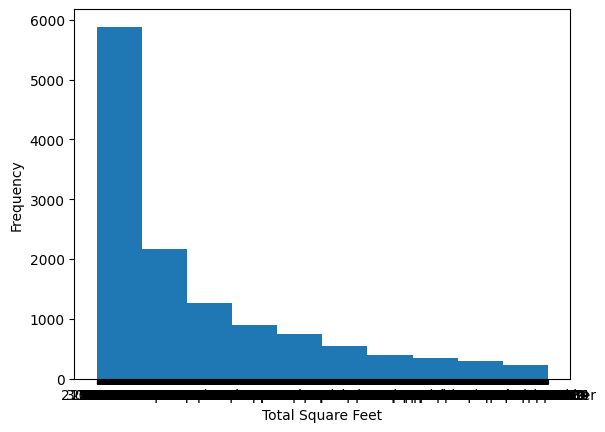

In [707]:
#histogram of total_sqft column
plt.hist(df['total_sqft'], bins=10)
plt.xlabel('Total Square Feet')
plt.ylabel('Frequency')
plt.show()

#first we need to convert the total_sqft column to numeric values as there are some values which are not numeric.

In [708]:
df['bath'].value_counts()

bath
2.0     6546
3.0     3180
4.0     1198
1.0      762
5.0      520
6.0      271
7.0      102
8.0       64
9.0       42
10.0      13
12.0       7
11.0       3
13.0       3
16.0       2
27.0       1
14.0       1
40.0       1
15.0       1
18.0       1
Name: count, dtype: int64

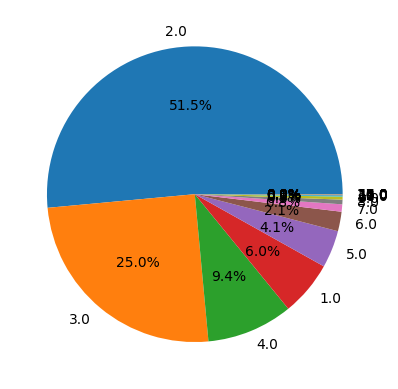

In [709]:
#pie chart of bath col
plt.pie(df['bath'].value_counts(), labels=df['bath'].value_counts().index, autopct='%1.1f%%')
plt.show()

In [710]:
df['balcony'].value_counts()

balcony
2.0    4846
1.0    4700
3.0    1630
0.0    1010
Name: count, dtype: int64

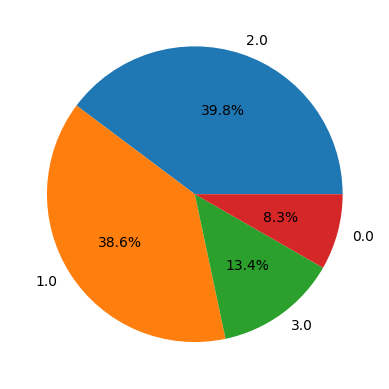

In [711]:
#pie chart of balcony col
plt.pie(df['balcony'].value_counts(), labels=df['balcony'].value_counts().index, autopct='%1.1f%%')
plt.show()

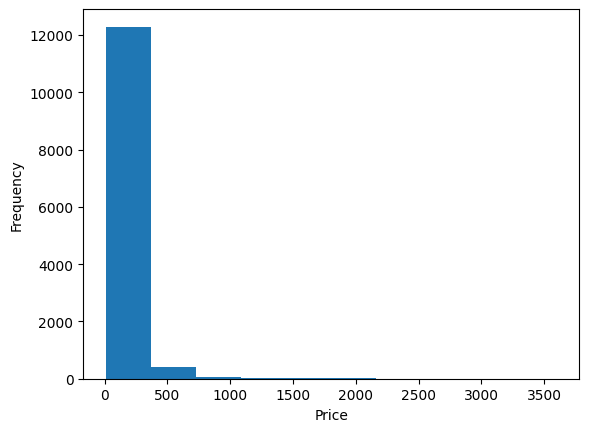

In [712]:
#histogram of the target variable- price
plt.hist(df['price'])
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

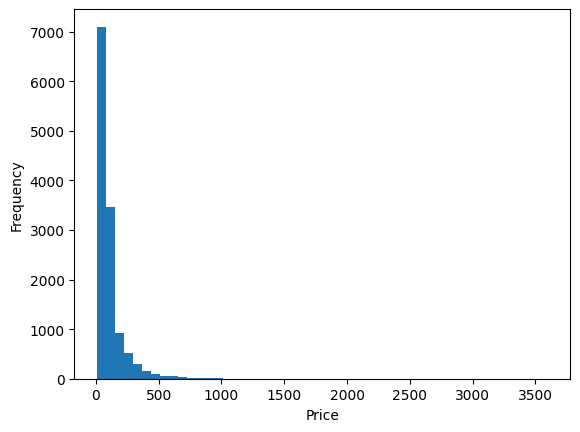

In [713]:
#histogram of the target variable- price
plt.hist(df['price'], bins=50)
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

In [714]:
#houses with pice more than 7 crore
df[df['price']>700]

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
159,Plot Area,Ready To Move,Mahalakshmi Layout,4 Bedroom,NaN,3750,4.0,0.0,760.0
408,Super built-up Area,19-Jan,Rajaji Nagar,7 BHK,NaN,12000,6.0,3.0,2200.0
605,Super built-up Area,19-Jan,Malleshwaram,7 BHK,NaN,12000,7.0,3.0,2200.0
743,Super built-up Area,Ready To Move,Cunningham Road,4 BHK,NaN,5270,4.0,3.0,1250.0
1044,Plot Area,Ready To Move,Binnamangala,6 Bedroom,NaN,3968,5.0,2.0,900.0
...,...,...,...,...,...,...,...,...,...
12987,Plot Area,Ready To Move,Dodsworth Layout,6 Bedroom,NaN,30400,4.0,2.0,1824.0
13067,Plot Area,Ready To Move,Defence Colony,10 Bedroom,NaN,7150,13.0,NaN,3600.0
13086,Super built-up Area,Ready To Move,Sindhi Colony,5 BHK,HMeuran,5665.84,7.0,NaN,988.0
13197,Plot Area,Ready To Move,Ramakrishnappa Layout,4 Bedroom,NaN,9200,4.0,NaN,2600.0


In [715]:
df.shape

(12791, 9)

In [716]:
#houses with price greater than 10 crore
df[df['price']>1000].shape

(45, 9)

In [717]:
#houses with price greater than 4 crore
df[df['price']>400].shape

(395, 9)

In [718]:
print('Houses with price greater than 2 crore:', df[df['price']>200].shape[0], 'Percentage:', (df[df['price']>200].shape[0]/df.shape[0])*100)
print('Houses with price greater than 3 crore:', df[df['price']>300].shape[0], 'Percentage:', (df[df['price']>300].shape[0]/df.shape[0])*100)
print('Houses with price greater than 4 crore:', df[df['price']>400].shape[0], 'Percentage:', (df[df['price']>400].shape[0]/df.shape[0])*100)
print('Houses with price greater than 7 crore:', df[df['price']>700].shape[0], 'Percentage:', (df[df['price']>700].shape[0]/df.shape[0])*100)
print('Houses with price greater than 10 crore:', df[df['price']>1000].shape[0], 'Percentage:', (df[df['price']>1000].shape[0]/df.shape[0])*100)


Houses with price greater than 2 crore: 1458 Percentage: 11.398639668516926
Houses with price greater than 3 crore: 717 Percentage: 5.605503869908529
Houses with price greater than 4 crore: 395 Percentage: 3.088108826518646
Houses with price greater than 7 crore: 107 Percentage: 0.8365256821202408
Houses with price greater than 10 crore: 45 Percentage: 0.3518098663122508


## Data Cleaning

### Issues with the dataset
- 529 duplicate rows (already removed) `Dirty data`
- missing values in location (1) ,size (16), society (5502), bath (73), balcony (609) `Dirty data`
- size - bhk and bedroom both are used `Consistency`
- in some of the total_sqft value is a range `Consistency`
- Uday Nagar and Udaya Nagar might be same places `Consistency`
- can convert size to an int
- 107 houses with price more than 700 lakhs (possibly outliers) - will handle later


In [719]:
#creating a copy of the original dataframe to work on
df1 = df.copy()

In [720]:
#percentage of missing values in society column
df1['society'].isnull().sum()/df1.shape[0]*100

np.float64(41.654288171370496)

Since more than 40% values are missing in the society column, we will drop this column.

In [721]:
#dropping the society column
df1.drop(columns=['society'], inplace=True)

In [722]:
df1.columns

Index(['area_type', 'availability', 'location', 'size', 'total_sqft', 'bath',
       'balcony', 'price'],
      dtype='object')

In [723]:
#correlation between area_type and price
df1.groupby('area_type')['price'].describe()

,count,mean,std,min,25%,50%,75%,max
area_type,,,,,,,,
Built-up Area,2398.0,104.797763,109.572191,9.00,48.0000,70.00,120.00,2050.0
Carpet Area,87.0,89.502356,73.446012,13.00,47.7025,70.00,100.00,500.0
Plot Area,1989.0,210.520543,254.944834,8.44,85.0000,140.00,240.00,3600.0
Super built-up Area,8317.0,94.315248,116.579057,8.00,48.0000,65.31,99.26,2912.0


area_type column is worth keeping.

In [724]:
df.shape

(12791, 9)

In [725]:
#drop the row with missing values in the location column
df1.dropna(subset=['location'], inplace=True)

In [726]:
df1.shape

(12790, 8)

In [727]:
#location column has some values with different spellings for the same location. We need to clean the location column.
#sort value counts of the location column alphabetically
df1['location'].value_counts().sort_index()

location
 Anekal                 1
 Banaswadi              1
 Basavangudi            1
 Bhoganhalli            1
 Devarabeesana Halli    6
                       ..
t.c palya               1
tc.palya                4
vinayakanagar           1
white field,kadugodi    1
whitefiled              1
Name: count, Length: 1305, dtype: int64

In [728]:
#making all the location values in lower case and stripping any leading or trailing spaces
df1['location'] = df1['location'].str.strip().str.lower()
df1['location'].value_counts().sort_index()

location
1 annasandrapalya                                   1
1 giri nagar                                        1
1 immadihalli                                       1
1 ramamurthy nagar                                  1
12th cross srinivas nagar banshankari 3rd stage     1
                                                   ..
yemlur                                              9
yemlur, old airport road,                           1
yeshwanthpur                                       83
yeshwanthpur industrial suburb                      3
zuzuvadi                                            1
Name: count, Length: 1283, dtype: int64

In [729]:
df1['location'].value_counts().sort_values(ascending=False)

location
whitefield              524
sarjapur  road          379
electronic city         289
kanakpura road          249
thanisandra             232
                       ... 
subhash nagar             1
jogupalya                 1
doddanakunte              1
duddanahalli              1
kathriguppe iv phase      1
Name: count, Length: 1283, dtype: int64

Top 10 locations with the most number of houses:
whitefield: 524, percentage: 4.10%
sarjapur  road: 379, percentage: 2.96%
electronic city: 289, percentage: 2.26%
kanakpura road: 249, percentage: 1.95%
thanisandra: 232, percentage: 1.81%
yelahanka: 210, percentage: 1.64%
marathahalli: 169, percentage: 1.32%
hebbal: 161, percentage: 1.26%
raja rajeshwari nagar: 159, percentage: 1.24%
uttarahalli: 157, percentage: 1.23%


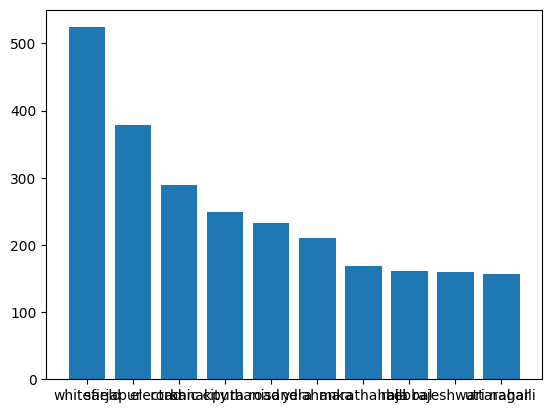

In [730]:
#bar graph of the top 10 locations with the most number of houses
top_10_locations = df1['location'].value_counts().sort_values(ascending=False).head(10)
plt.bar(top_10_locations.index, top_10_locations.values)

print('Top 10 locations with the most number of houses:')
for location, count in top_10_locations.items():
    print(f'{location}: {count}, percentage: {(count/df1.shape[0])*100:.2f}%')

In [731]:
#creating a copy of the dataframe to work on
df2 = df1.copy()

In [732]:
#grouping locations with less than 10 houses into a single category called 'other'
df2['location'] = df2['location'].apply(lambda x: x if df2['location'].value_counts()[x] >= 10 else 'other')
df2['location'].value_counts().sort_values(ascending=False)

location
other                    2763
whitefield                524
sarjapur  road            379
electronic city           289
kanakpura road            249
                         ... 
kalkere                    10
1st block koramangala      10
gunjur palya               10
dodsworth layout           10
nagadevanahalli            10
Name: count, Length: 251, dtype: int64

In [733]:
#number of other locations after grouping
df2[df2['location']=='other'].shape[0]

2763

In [734]:
#can drop the availability column as it does not have any effect on the price of the house (domain knowledge) 
df2 = df2.drop(columns=['availability'])

In [735]:
df2.sample()

,area_type,location,size,total_sqft,bath,balcony,price
4908,Built-up Area,talaghattapura,3 BHK,2254,3.0,2.0,170.0


In [736]:
df2['size'].value_counts()

size
2 BHK         4931
3 BHK         4119
4 Bedroom      824
4 BHK          574
3 Bedroom      535
1 BHK          521
2 Bedroom      314
5 Bedroom      291
6 Bedroom      191
1 Bedroom      104
8 Bedroom       84
7 Bedroom       82
5 BHK           59
9 Bedroom       46
6 BHK           30
7 BHK           17
1 RK            13
10 Bedroom      12
9 BHK            8
8 BHK            5
11 BHK           2
10 BHK           2
11 Bedroom       2
27 BHK           1
19 BHK           1
43 Bedroom       1
16 BHK           1
14 BHK           1
12 Bedroom       1
13 BHK           1
18 Bedroom       1
Name: count, dtype: int64

In [737]:
# identify every format used in the size column and count its frequency and percentage of each format
size_formats = df2['size'].str.extract(
    r'^\s*(?P<number>\d+(?:\.\d+)?)\s*(?P<format>.*)\s*$',
    expand=True
)

size_formats['format'] = size_formats['format'].replace('', 'Missing format')
size_formats['format'].value_counts(dropna=False)/size_formats.shape[0]*100

format
BHK        80.320563
Bedroom    19.452697
NaN         0.125098
RK          0.101642
Name: count, dtype: float64

In [738]:
#drop the nan rows in the size column - cca
df2 = df2.dropna(subset=['size'])

In [739]:
#print the number of rows which have the range format in total_sqft column
print(df2[df2['total_sqft'].str.contains('-')].shape[0])

192


In [740]:
unit_to_sqft = {
    'sq. meter': 10.764, 'sq.meter': 10.764,
    'sq. yards': 9, 'acres': 43560,
    'cents': 435.6, 'guntha': 1089, 'perch': 272.25
}

def convert_sqft_to_num(x):
    x = x.strip().lower()
    if '-' in x:
        tokens = x.split('-')
        return (float(tokens[0]) + float(tokens[1])) / 2
    for unit, factor in unit_to_sqft.items():
        if unit in x:
            number = float(x.replace(unit, '').strip())
            return number * factor
    try:
        return float(x)
    except:
        return None


df2['total_sqft'] = df2['total_sqft'].apply(convert_sqft_to_num)

In [741]:
#checking the row with the range value in the total_sqft column
df2.iloc[224,:]

area_type     Super built-up  Area
location               devanahalli
size                         3 BHK
total_sqft                  1630.0
bath                           NaN
balcony                        NaN
price                        74.82
Name: 224, dtype: object

In [742]:
#try converting the total_sqft column to float type
df2['total_sqft'] = df2['total_sqft'].astype(float)

In [743]:
#drop the null values in the total_sqft column
df2 = df2.dropna(subset=['total_sqft'])

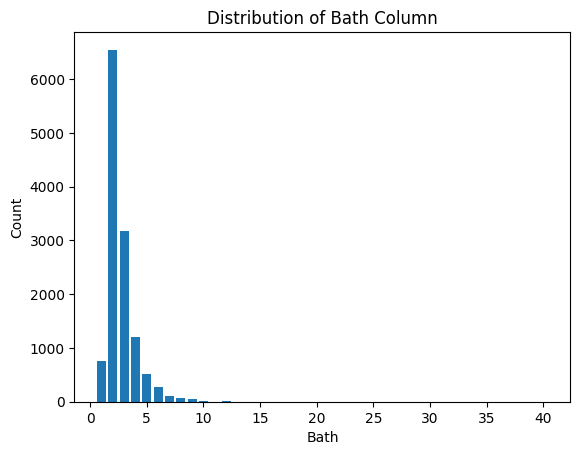

In [744]:
#distribution of bath column- bar graph
plt.bar(df2['bath'].value_counts().index, df2['bath'].value_counts().values)
plt.xlabel('Bath')
plt.ylabel('Count')
plt.title('Distribution of Bath Column')
plt.show()

In [745]:
#impute the missing values in bath column with the median value of the bath column- skewed distribution
df2['bath'].fillna(df2['bath'].median(), inplace=True)

C:\Users\kanik\AppData\Local\Temp\ipykernel_35100\1304439825.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df2['bath'].fillna(df2['bath'].median(), inplace=True)


In [746]:
#inspect balcony column
df2['balcony'].value_counts()

balcony
2.0    4845
1.0    4699
3.0    1630
0.0    1010
Name: count, dtype: int64

In [747]:
#check the percentage of missing values in the balcony column grouped by area_type
df2.groupby('area_type')['balcony'].apply(lambda x: x.isnull().mean())*100

area_type
Built-up  Area          4.503753
Carpet  Area            5.747126
Plot  Area              8.722110
Super built-up  Area    3.655604
Name: balcony, dtype: float64

In [748]:
df2.corr(numeric_only=True)

,total_sqft,bath,balcony,price
total_sqft,1.000000,0.052639,0.006303,0.048527
bath,0.052639,1.000000,0.200320,0.451429
balcony,0.006303,0.200320,1.000000,0.118631
price,0.048527,0.451429,0.118631,1.000000


In [749]:
df2.isnull().sum()/df2.shape[0]*100

area_type     0.000000
location      0.000000
size          0.000000
total_sqft    0.000000
bath          0.000000
balcony       4.611289
price         0.000000
dtype: float64

In [750]:
#dropping the balcony column as it has low correlation with the target variable
df2.drop(columns=['balcony'], inplace=True)

In [751]:
df2.shape

(12773, 6)

In [752]:
df2.isnull().sum()

area_type     0
location      0
size          0
total_sqft    0
bath          0
price         0
dtype: int64

Feature engineering

In [753]:
# size --> no_of_bedrooms and is_rk
df2['no_of_bedrooms'] = df2['size'].str.extract(r'(\d+)').astype(int)
df2['is_rk'] = df2['size'].str.contains('RK').astype(int) 
df2.sample()

,area_type,location,size,total_sqft,bath,price,no_of_bedrooms,is_rk
2111,Super built-up Area,electronic city,3 BHK,1111.0,3.0,50.0,3,0


In [754]:
df2['no_of_bedrooms'].value_counts()

no_of_bedrooms
2     5245
3     4654
4     1398
1      637
5      350
6      221
7       99
8       89
9       54
10      14
11       4
27       1
19       1
16       1
43       1
14       1
12       1
13       1
18       1
Name: count, dtype: int64

bedrooms = 43 is an outlier

In [755]:
df2.drop(columns=['size'], inplace=True)

In [756]:
# rearranging the columns in the dataframe
# Keep is_rk until it is used to calculate sqft_per_room.
df2 = df2[['area_type', 'location', 'no_of_bedrooms', 'is_rk', 'total_sqft', 'bath', 'price']]

In [757]:
df2[df2['no_of_bedrooms']>11]

,area_type,location,no_of_bedrooms,is_rk,total_sqft,bath,price
1718,Super built-up Area,other,27,0,8000.0,27.0,230.0
3379,Super built-up Area,other,19,0,2000.0,16.0,490.0
3609,Super built-up Area,other,16,0,10000.0,16.0,550.0
4684,Plot Area,munnekollal,43,0,2400.0,40.0,660.0
4916,Super built-up Area,other,14,0,1250.0,15.0,125.0
6533,Plot Area,mysore road,12,0,2232.0,6.0,300.0
9935,Super built-up Area,other,13,0,5425.0,13.0,275.0
11559,Plot Area,other,18,0,1200.0,18.0,200.0


In [758]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12773 entries, 0 to 13318
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area_type       12773 non-null  object 
 1   location        12773 non-null  object 
 2   no_of_bedrooms  12773 non-null  int64  
 3   is_rk           12773 non-null  int64  
 4   total_sqft      12773 non-null  float64
 5   bath            12773 non-null  float64
 6   price           12773 non-null  float64
dtypes: float64(3), int64(2), object(2)
memory usage: 798.3+ KB


In [759]:
# new feature- sqft_per_room
# If is_rk == 1, exclude the two assumed balconies from the denominator.
denominator = np.where(
    df2['is_rk'] == 1,
    df2['no_of_bedrooms'] + df2['bath'],
    df2['no_of_bedrooms'] + df2['bath'] + 2
)
df2['sqft_per_room'] = df2['total_sqft'] / denominator

# drop is_rk column as it is not needed anymore
df2.drop(columns=['is_rk'], inplace=True)

# rearranging the columns in the dataframe
df2 = df2[['area_type', 'location', 'no_of_bedrooms', 'bath', 'total_sqft', 'sqft_per_room', 'price']]
df2.head()

,area_type,location,no_of_bedrooms,bath,total_sqft,sqft_per_room,price
0,Super built-up Area,electronic city phase ii,2,2.0,1056.0,176.000000,39.07
1,Plot Area,chikka tirupathi,4,5.0,2600.0,236.363636,120.00
2,Built-up Area,uttarahalli,3,2.0,1440.0,205.714286,62.00
3,Super built-up Area,lingadheeranahalli,3,3.0,1521.0,190.125000,95.00
4,Super built-up Area,kothanur,2,2.0,1200.0,200.000000,51.00


In [760]:
df2['sqft_per_room'].describe()

count     12773.000000
mean        251.918372
std        2251.713076
min           0.100000
25%         170.250000
50%         196.625000
75%         221.222222
max      217800.000000
Name: sqft_per_room, dtype: float64

In [761]:
df_cleaned = df2.copy()

Outlier detection, Removal and EDA

In [762]:
df_cleaned.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12773 entries, 0 to 13318
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area_type       12773 non-null  object 
 1   location        12773 non-null  object 
 2   no_of_bedrooms  12773 non-null  int64  
 3   bath            12773 non-null  float64
 4   total_sqft      12773 non-null  float64
 5   sqft_per_room   12773 non-null  float64
 6   price           12773 non-null  float64
dtypes: float64(4), int64(1), object(2)
memory usage: 798.3+ KB


In [763]:
df_cleaned.isnull().sum()

area_type         0
location          0
no_of_bedrooms    0
bath              0
total_sqft        0
sqft_per_room     0
price             0
dtype: int64

In [764]:
df_cleaned.head()

,area_type,location,no_of_bedrooms,bath,total_sqft,sqft_per_room,price
0,Super built-up Area,electronic city phase ii,2,2.0,1056.0,176.000000,39.07
1,Plot Area,chikka tirupathi,4,5.0,2600.0,236.363636,120.00
2,Built-up Area,uttarahalli,3,2.0,1440.0,205.714286,62.00
3,Super built-up Area,lingadheeranahalli,3,3.0,1521.0,190.125000,95.00
4,Super built-up Area,kothanur,2,2.0,1200.0,200.000000,51.00


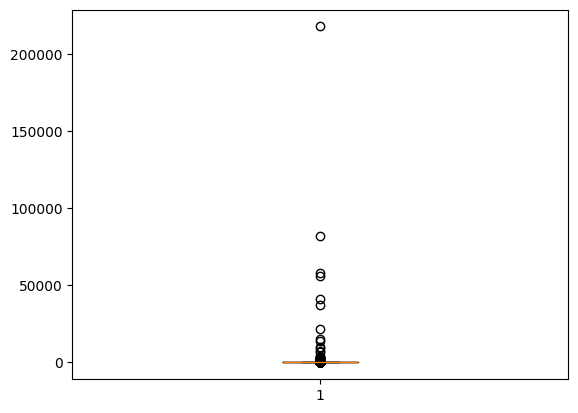

In [765]:
#boxplot of sqft_per_room column
plt.boxplot(df_cleaned['sqft_per_room'])
plt.show()

<Axes: ylabel='Density'>

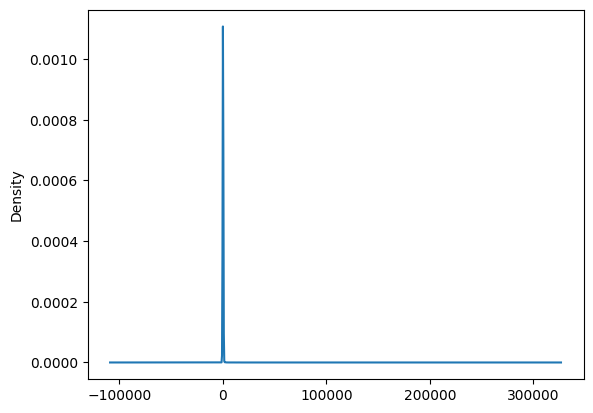

In [766]:
#kde plot of sqft_per_room column
df_cleaned['sqft_per_room'].plot(kind='kde')

In [767]:
#check the skewness of the sqft_per_room column
df_cleaned['sqft_per_room'].skew()

np.float64(77.76526553581266)

In [768]:
#skewed data distribution of sqft_per_room column- trim upper outliers
upper_limit = df_cleaned['sqft_per_room'].quantile(0.99)
upper_limit

np.float64(528.7733333333375)

In [769]:
#lower limit of sqft_per_room column
lower_limit = 100

In [770]:
#percentage of rows with sqft_per_room greater than upper_limit or less than lower_limit
print('Percentage of rows with sqft_per_room greater than upper_limit: {0:.2f}%'.format(df_cleaned[(df_cleaned['sqft_per_room']>upper_limit)].shape[0]/df_cleaned.shape[0]*100))
print('Percentage of rows with sqft_per_room less than lower_limit: {0:.2f}%'.format(df_cleaned[df_cleaned['sqft_per_room']<lower_limit].shape[0]/df_cleaned.shape[0]*100))
print('Percentage of rows with sqft_per_room greater than upper_limit or less than lower_limit: {0:.2f}%'.format(df_cleaned[(df_cleaned['sqft_per_room']>upper_limit) | (df_cleaned['sqft_per_room']<lower_limit)].shape[0]/df_cleaned.shape[0]*100))

Percentage of rows with sqft_per_room greater than upper_limit: 1.00%
Percentage of rows with sqft_per_room less than lower_limit: 4.29%
Percentage of rows with sqft_per_room greater than upper_limit or less than lower_limit: 5.29%


In [771]:
df_cleaned[df_cleaned['sqft_per_room']>upper_limit]

,area_type,location,no_of_bedrooms,bath,total_sqft,sqft_per_room,price
60,Plot Area,other,3,3.0,4395.0,549.375000,240.0
122,Super built-up Area,hebbal,4,4.0,5611.5,561.150000,477.0
408,Super built-up Area,rajaji nagar,7,6.0,12000.0,800.000000,2200.0
440,Plot Area,whitefield,4,4.0,11890.0,1189.000000,700.0
514,Plot Area,banashankari stage iii,4,4.0,8500.0,850.000000,145.0
...,...,...,...,...,...,...,...
12987,Plot Area,dodsworth layout,6,4.0,30400.0,2533.333333,1824.0
13095,Super built-up Area,other,4,6.0,6652.0,554.333333,660.0
13119,Plot Area,other,4,6.0,6688.0,557.333333,700.0
13197,Plot Area,other,4,4.0,9200.0,920.000000,2600.0
